In [1]:
!pip install -q -U ultralytics kagglehub scikit-learn seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 36.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 51.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 6.8 MB/s eta 0:00:00


In [2]:
import os
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

from ultralytics import YOLO

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download(
    "alicjalena/pv-panel-defect-dataset"
)

print("Path to dataset files:")
print(path)

100%|██████████| 473M/473M [00:27<00:00, 18.1MB/s]

Extracting files...


Path to dataset files:
/root/.cache/kagglehub/datasets/alicjalena/pv-panel-defect-dataset/versions/1


In [4]:
dataset_path = Path(path)

print("Dataset contents:\n")

for item in dataset_path.iterdir():
    print(
        f"{item.name:30} "
        f"{'DIR' if item.is_dir() else 'FILE'}"
    )

Dataset contents:

test                           DIR
train                          DIR
val                            DIR


In [5]:
for split in ["train", "val", "test"]:

    split_path = dataset_path / split

    print(f"\n===== {split.upper()} =====")

    if not split_path.exists():
        print(f"WARNING: {split} folder not found!")
        continue

    for class_folder in sorted(split_path.iterdir()):

        if class_folder.is_dir():

            images = [
                f for f in class_folder.iterdir()
                if f.suffix.lower() in [
                    ".jpg",
                    ".jpeg",
                    ".png",
                    ".bmp",
                    ".webp"
                ]
            ]

            print(
                f"{class_folder.name:20}: "
                f"{len(images)} images"
            )


===== TRAIN =====
Bird-drop           : 177 images
Clean               : 169 images
Dusty               : 162 images
Electrical-damage   : 135 images
Physical-Damage     : 132 images
Snow-Covered        : 154 images

===== VAL =====
Bird-drop           : 104 images
Clean               : 102 images
Dusty               : 97 images
Electrical-damage   : 77 images
Physical-Damage     : 78 images
Snow-Covered        : 92 images

===== TEST =====
Bird-drop           : 17 images
Clean               : 18 images
Dusty               : 16 images
Electrical-damage   : 13 images
Physical-Damage     : 15 images
Snow-Covered        : 16 images


In [6]:
CLASSES = [
    "Bird-drop",
    "Clean",
    "Dusty",
    "Electrical-damage",
    "Physical-Damage",
    "Snow-Covered"
]

print("Number of classes:", len(CLASSES))

for i, cls in enumerate(CLASSES):
    print(i, cls)

Number of classes: 6
0 Bird-drop
1 Clean
2 Dusty
3 Electrical-damage
4 Physical-Damage
5 Snow-Covered


In [7]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

dataset_counts = {}

for split in ["train", "val", "test"]:

    dataset_counts[split] = {}

    for class_name in CLASSES:

        folder = dataset_path / split / class_name

        count = 0

        if folder.exists():

            count = sum(
                1
                for f in folder.iterdir()
                if f.is_file()
                and f.suffix.lower() in IMAGE_EXTENSIONS
            )

        dataset_counts[split][class_name] = count


for split in ["train", "val", "test"]:

    print(f"\n===== {split.upper()} =====")

    total = 0

    for cls in CLASSES:

        count = dataset_counts[split][cls]

        print(f"{cls:20}: {count}")

        total += count

    print(f"{'TOTAL':20}: {total}")


===== TRAIN =====
Bird-drop           : 177
Clean               : 169
Dusty               : 162
Electrical-damage   : 135
Physical-Damage     : 132
Snow-Covered        : 154
TOTAL               : 929

===== VAL =====
Bird-drop           : 104
Clean               : 102
Dusty               : 97
Electrical-damage   : 77
Physical-Damage     : 78
Snow-Covered        : 92
TOTAL               : 550

===== TEST =====
Bird-drop           : 17
Clean               : 18
Dusty               : 16
Electrical-damage   : 13
Physical-Damage     : 15
Snow-Covered        : 16
TOTAL               : 95


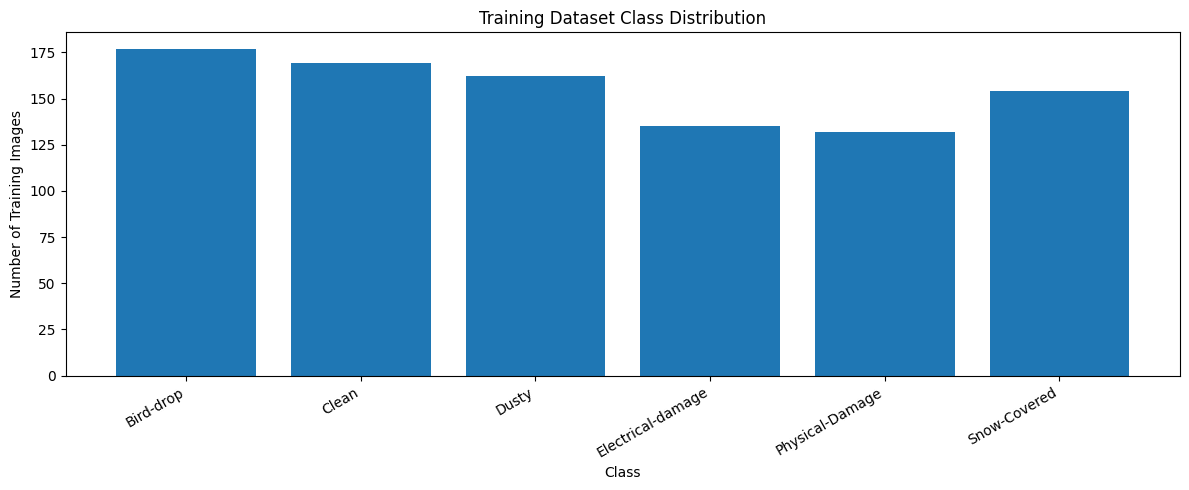

In [8]:
train_counts = [
    dataset_counts["train"][cls]
    for cls in CLASSES
]

plt.figure(figsize=(12, 5))

plt.bar(CLASSES, train_counts)

plt.xlabel("Class")
plt.ylabel("Number of Training Images")
plt.title("Training Dataset Class Distribution")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

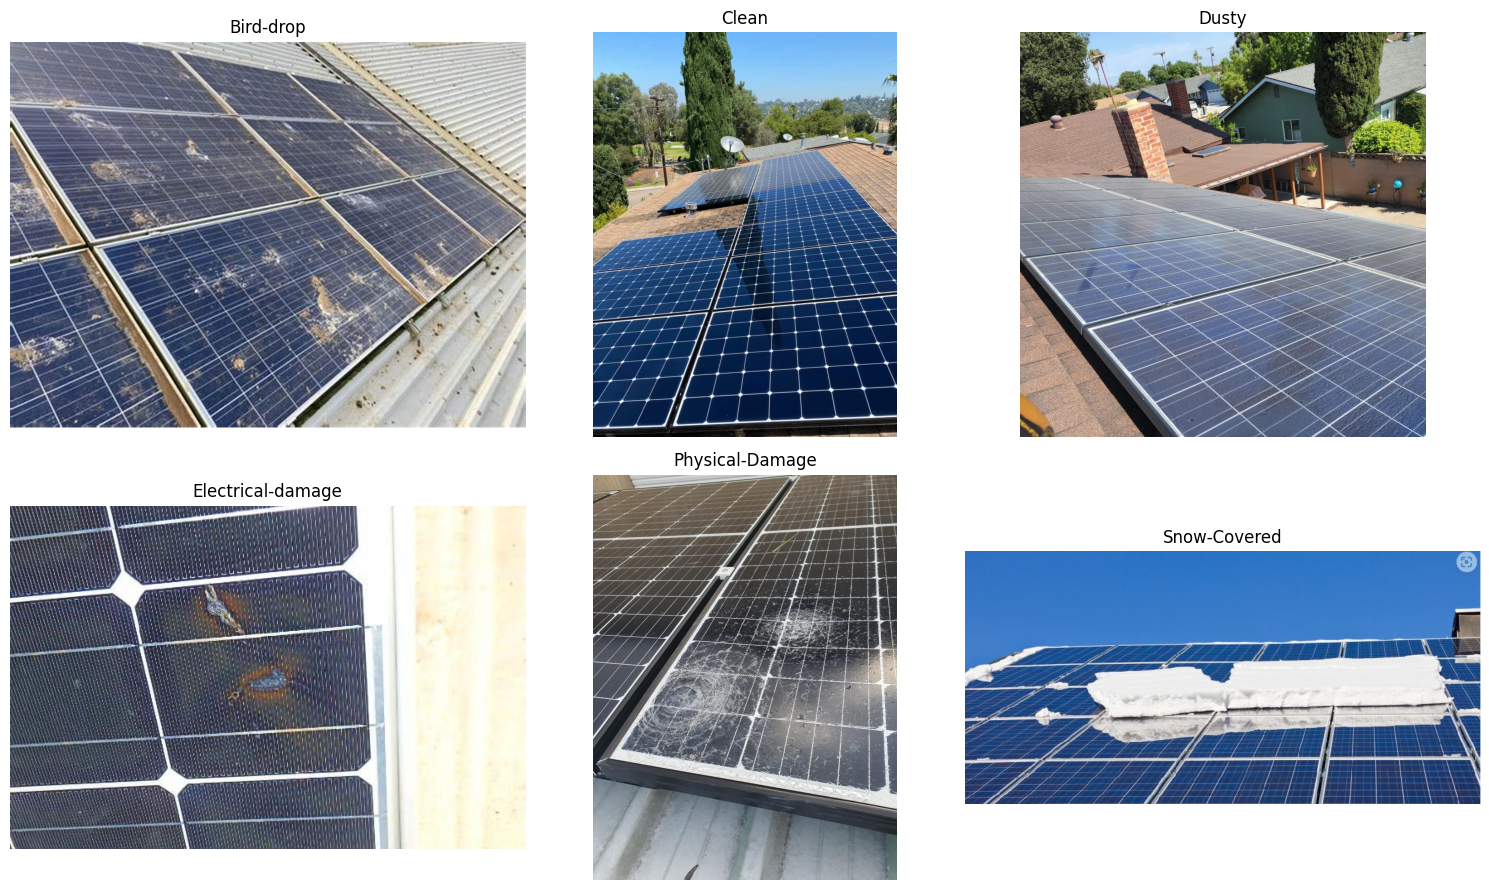

In [9]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)

for ax, class_name in zip(axes.flat, CLASSES):

    folder = dataset_path / "train" / class_name

    images = [
        f for f in folder.iterdir()
        if f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    image_path = random.choice(images)

    img = Image.open(image_path)

    ax.imshow(img)

    ax.set_title(class_name)

    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
model = YOLO("yolo26n-cls.pt")

In [11]:
results = model.train(
    data=path,

    epochs=80,

    imgsz=320,

    batch=32,

    patience=15,

    device=0,

    workers=2,

    # Moderate augmentation
    degrees=10,
    translate=0.1,
    scale=0.2,
    fliplr=0.5,

    project="/content/pv_runs",

    name="yolo26n_pv_320",

    pretrained=True,

    verbose=True
)

Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/root/.cache/kagglehub/datasets/alicjalena/pv-panel-defect-dataset/versions/1, degrees=10, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, 

In [12]:
best_model = YOLO("/content/pv_runs/yolo26n_pv_320/weights/best.pt")

In [13]:
val_results = best_model.val(
    data=path,
    split="val",
    imgsz=320,
    batch=32,
    device=0
)

print(
    "Validation Top-1 Accuracy:",
    val_results.top1
)

print(
    "Validation Top-5 Accuracy:",
    val_results.top5
)

Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-cls summary (fused): 47 layers, 1,533,710 parameters, 0 gradients, 3.2 GFLOPs
train: /root/.cache/kagglehub/datasets/alicjalena/pv-panel-defect-dataset/versions/1/train... found 929 images in 6 classes ✅ 
val: /root/.cache/kagglehub/datasets/alicjalena/pv-panel-defect-dataset/versions/1/val... found 550 images in 6 classes ✅ 
test: /root/.cache/kagglehub/datasets/alicjalena/pv-panel-defect-dataset/versions/1/test... found 95 images in 6 classes ✅ 
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3393.2±2095.4 MB/s, size: 736.3 KB)
val: Scanning /root/.cache/kagglehub/datasets/alicjalena/pv-panel-defect-dataset/versions/1/val... 550 images, 0 corrupt: 100% ━━━━━━━━━━━━ 550/550 153.8Mit/s 0.0s
val: /root/.cache/kagglehub/datasets/alicjalena/pv-panel-defect-dataset/versions/1/val/Clean/Clean (13).jpg: corrupt JPEG restored and saved
val: /root/.cache/kagglehub/datasets/alicjalena/pv-panel-defect-d

In [14]:
test_results = best_model.val(
    data=path,
    split="test",
    imgsz=320,
    batch=32,
    device=0
)

print(
    "TEST Top-1 Accuracy:",
    test_results.top1
)

print(
    "TEST Top-5 Accuracy:",
    test_results.top5
)

Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-cls summary (fused): 47 layers, 1,533,710 parameters, 0 gradients, 3.2 GFLOPs
train: /root/.cache/kagglehub/datasets/alicjalena/pv-panel-defect-dataset/versions/1/train... found 929 images in 6 classes ✅ 
val: /root/.cache/kagglehub/datasets/alicjalena/pv-panel-defect-dataset/versions/1/val... found 550 images in 6 classes ✅ 
test: /root/.cache/kagglehub/datasets/alicjalena/pv-panel-defect-dataset/versions/1/test... found 95 images in 6 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1050.7±127.5 MB/s, size: 60.5 KB)
test: Scanning /root/.cache/kagglehub/datasets/alicjalena/pv-panel-defect-dataset/versions/1/test... 95 images, 0 corrupt: 100% ━━━━━━━━━━━━ 95/95 1.7Kit/s 0.1s
test: /root/.cache/kagglehub/datasets/alicjalena/pv-panel-defect-dataset/versions/1/test/Electrical-damage/Electrical (103).jpg: corrupt JPEG restored and saved
test: New cache created: /root/.cache/kagglehub/d

In [15]:
test_path = dataset_path / "test"

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(CLASSES)
}

y_true = []
y_pred = []

misclassified = []

for true_class in CLASSES:

    class_folder = test_path / true_class

    image_files = [
        f for f in class_folder.iterdir()
        if f.is_file()
        and f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    print(
        f"Processing {true_class}: "
        f"{len(image_files)} images"
    )

    for image_path in image_files:

        results = best_model.predict(
            source=str(image_path),
            imgsz=320,
            device=0,
            verbose=False
        )

        result = results[0]

        pred_id = int(result.probs.top1)

        pred_class = result.names[pred_id]

        confidence = float(
            result.probs.top1conf
        )

        true_id = class_to_idx[true_class]

        y_true.append(true_id)
        y_pred.append(pred_id)

        # Save mistakes
        if pred_class != true_class:

            misclassified.append({
                "image": str(image_path),
                "true": true_class,
                "predicted": pred_class,
                "confidence": confidence
            })

print("\nFinished.")
print(
    "Number of test images:",
    len(y_true)
)

print(
    "Number of incorrect predictions:",
    len(misclassified)
)

Processing Bird-drop: 17 images
Processing Clean: 18 images
Processing Dusty: 16 images
Processing Electrical-damage: 13 images
Processing Physical-Damage: 15 images
Processing Snow-Covered: 16 images

Finished.
Number of test images: 95
Number of incorrect predictions: 3


In [16]:
accuracy = accuracy_score(
    y_true,
    y_pred
)

print(
    f"Test Accuracy: {accuracy:.4f}"
)

print(
    f"Test Accuracy: {accuracy * 100:.2f}%"
)

Test Accuracy: 0.9684
Test Accuracy: 96.84%


In [17]:
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    digits=4
)

print(report)

                   precision    recall  f1-score   support

        Bird-drop     1.0000    0.9412    0.9697        17
            Clean     0.9444    0.9444    0.9444        18
            Dusty     0.9412    1.0000    0.9697        16
Electrical-damage     1.0000    0.9231    0.9600        13
  Physical-Damage     0.9375    1.0000    0.9677        15
     Snow-Covered     1.0000    1.0000    1.0000        16

         accuracy                         0.9684        95
        macro avg     0.9705    0.9681    0.9686        95
     weighted avg     0.9697    0.9684    0.9684        95



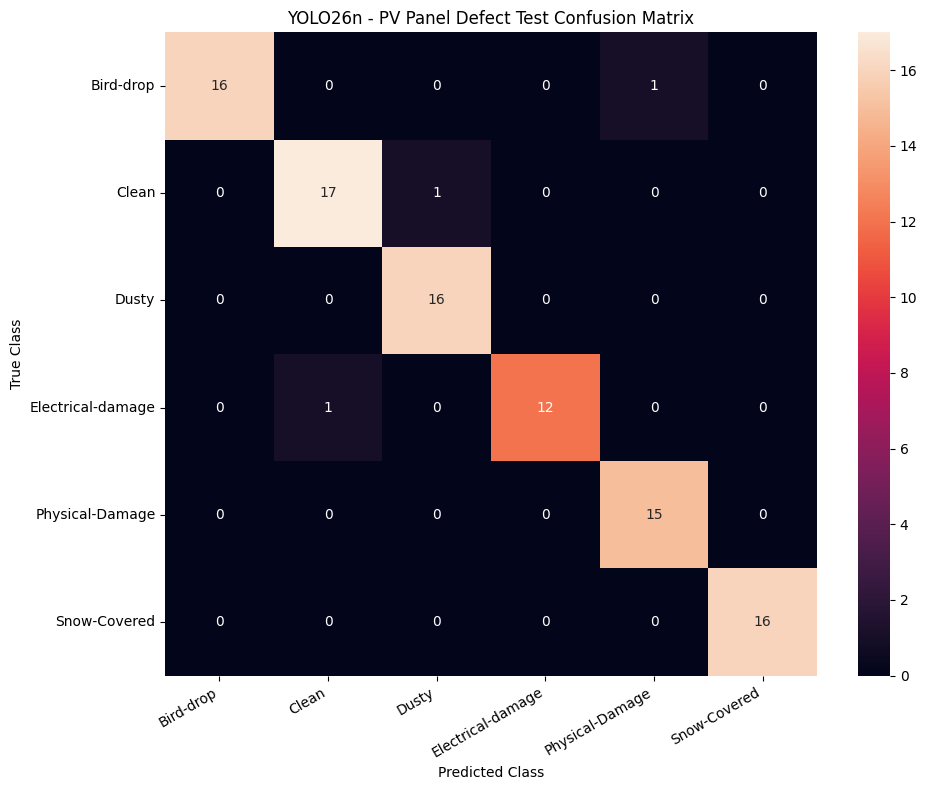

In [18]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.title(
    "YOLO26n - PV Panel Defect Test Confusion Matrix"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.yticks(rotation=0)

plt.tight_layout()

plt.show()

In [19]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [20]:
import os

drive_path = '/content/drive/MyDrive/PV_Panel_Defect_Classification'
os.makedirs(drive_path, exist_ok=True)

print(f"Created directory: {drive_path}")

Created directory: /content/drive/MyDrive/PV_Panel_Defect_Classification


### Saving the trained model

In [21]:
import shutil

model_save_path = os.path.join(drive_path, 'best_yolo26n_pv_320.pt')
shutil.copy('/content/pv_runs/yolo26n_pv_320/weights/best.pt', model_save_path)

print(f"Trained model saved to: {model_save_path}")

Trained model saved to: /content/drive/MyDrive/PV_Panel_Defect_Classification/best_yolo26n_pv_320.pt


### Saving the plots

In [22]:
# Save the Training Dataset Class Distribution plot
plt.figure(figsize=(12, 5))
plt.bar(CLASSES, train_counts)
plt.xlabel("Class")
plt.ylabel("Number of Training Images")
plt.title("Training Dataset Class Distribution")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(drive_path, 'training_class_distribution.png'))
plt.close()

print("Saved training_class_distribution.png")

# Save the Sample Images per Class plot
fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)

for ax, class_name in zip(axes.flat, CLASSES):
    folder = dataset_path / "train" / class_name
    images = [
        f for f in folder.iterdir()
        if f.suffix.lower() in IMAGE_EXTENSIONS
    ]
    if images:
        image_path = random.choice(images)
        img = Image.open(image_path)
        ax.imshow(img)
        ax.set_title(class_name)
        ax.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(drive_path, 'sample_images_per_class.png'))
plt.close()

print("Saved sample_images_per_class.png")

# Save the Confusion Matrix plot
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("YOLO26n - PV Panel Defect Test Confusion Matrix")
plt.xticks(
    rotation=30,
    ha="right"
)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(drive_path, 'confusion_matrix.png'))
plt.close()

print("Saved confusion_matrix.png")

Saved training_class_distribution.png
Saved sample_images_per_class.png
Saved confusion_matrix.png


### Test with a new image

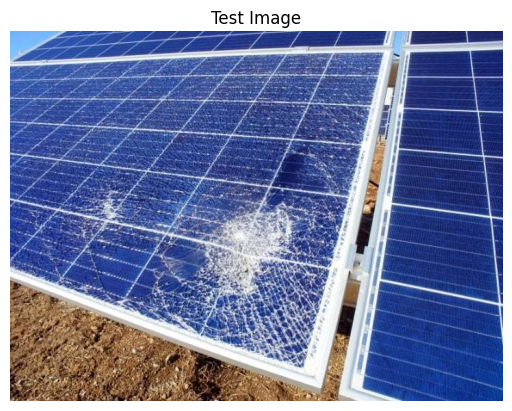

Predicted Class: Physical-Damage
Confidence: 1.0000


In [24]:
test_image_path = '/content/Damaged-solar-panel-cracked-glass.jpg'

# Load and display the image
img = Image.open(test_image_path)
plt.imshow(img)
plt.axis('off')
plt.title('Test Image')
plt.show()

# Make a prediction with the best_model
prediction_results = best_model.predict(
    source=test_image_path,
    imgsz=320,
    device=0,
    verbose=False
)

# Extract and print the prediction details
pred_result = prediction_results[0]
predicted_id = int(pred_result.probs.top1)
predicted_class_name = pred_result.names[predicted_id]
prediction_confidence = float(pred_result.probs.top1conf)

print(f"Predicted Class: {predicted_class_name}")
print(f"Confidence: {prediction_confidence:.4f}")